In [1]:
install.packages("lime")
install.packages("ranger")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘foreach’, ‘shape’, ‘assertthat’, ‘glmnet’, ‘gower’, ‘RcppEigen’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(lime)
library(ranger)

In [3]:
loan_data<- data.frame(
  Income = c(
    25000, 45000, 30000, 70000, 28000,
    60000, 35000, 80000, 22000, 50000,
    40000, 90000, 27000, 65000, 32000,
    75000, 29000, 55000, 38000, 100000
  ),
LoanAmount = c(
    500000, 300000, 450000, 200000, 600000,
    250000, 500000, 150000, 700000, 300000,
    450000, 100000, 650000, 250000, 550000,
    180000, 600000, 350000, 400000, 120000
  ),
CreditScore = c(
    550, 720, 580, 780, 520,
    750, 600, 800, 510, 690,
    620, 820, 530, 740, 590,
    770, 540, 680, 610, 850
  ),
PreviousDefaults = c(
    3, 0, 2, 0, 4,
    0, 2, 0, 5, 1,
    2, 0, 4, 0, 3,
    0, 4, 1, 2, 0
  ),
  Default = c(
    "Yes", "No", "Yes", "No", "Yes",
    "No", "Yes", "No", "Yes", "No",
    "Yes", "No", "Yes", "No", "Yes",
    "No", "Yes", "No", "Yes", "No"
  )
)


In [4]:
loan_data$Default<- as.factor(loan_data$Default)

In [5]:
print(loan_data)

   Income LoanAmount CreditScore PreviousDefaults Default
1   25000     500000         550                3     Yes
2   45000     300000         720                0      No
3   30000     450000         580                2     Yes
4   70000     200000         780                0      No
5   28000     600000         520                4     Yes
6   60000     250000         750                0      No
7   35000     500000         600                2     Yes
8   80000     150000         800                0      No
9   22000     700000         510                5     Yes
10  50000     300000         690                1      No
11  40000     450000         620                2     Yes
12  90000     100000         820                0      No
13  27000     650000         530                4     Yes
14  65000     250000         740                0      No
15  32000     550000         590                3     Yes
16  75000     180000         770                0      No
17  29000     

In [6]:
loan_model<- ranger(
  Default ~ Income +
LoanAmount +
CreditScore +
PreviousDefaults,
  data = loan_data,
  probability = TRUE,
num.trees = 100
)
print(loan_model)


Ranger result

Call:
 ranger(Default ~ Income + LoanAmount + CreditScore + PreviousDefaults,      data = loan_data, probability = TRUE, num.trees = 100) 

Type:                             Probability estimation 
Number of trees:                  100 
Sample size:                      20 
Number of independent variables:  4 
Mtry:                             2 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.006398317 


In [7]:
predictions <- predict(
loan_model,
loan_data
)
print(predictions$predictions)


        No  Yes
 [1,] 0.00 1.00
 [2,] 0.90 0.10
 [3,] 0.01 0.99
 [4,] 1.00 0.00
 [5,] 0.00 1.00
 [6,] 1.00 0.00
 [7,] 0.01 0.99
 [8,] 1.00 0.00
 [9,] 0.00 1.00
[10,] 1.00 0.00
[11,] 0.01 0.99
[12,] 1.00 0.00
[13,] 0.00 1.00
[14,] 1.00 0.00
[15,] 0.00 1.00
[16,] 1.00 0.00
[17,] 0.00 1.00
[18,] 0.99 0.01
[19,] 0.04 0.96
[20,] 1.00 0.00


In [8]:
explainer <- lime(
loan_data[, c(
    "Income",
    "LoanAmount",
    "CreditScore",
    "PreviousDefaults"
  )],
loan_model
)


In [9]:
customer <- loan_data[1, c(
  "Income",
  "LoanAmount",
  "CreditScore",
  "PreviousDefaults"
)]
print(customer)



  Income LoanAmount CreditScore PreviousDefaults
1  25000      5e+05         550                3


In [12]:
explanation <- explain(
  customer,
  explainer,
  labels = "Yes",
n_features = 4
)
print(explanation)

contradicting_features <- explanation[
  explanation$feature_weight < 0,
]
print(contradicting_features)


# A tibble: 4 × 13
  model_type    case  label label_prob model_r2 model_intercept model_prediction
  <chr>         <chr> <chr>      <dbl>    <dbl>           <dbl>            <dbl>
1 classificati… 1     Yes            1    0.332           0.366            0.972
2 classificati… 1     Yes            1    0.332           0.366            0.972
3 classificati… 1     Yes            1    0.332           0.366            0.972
4 classificati… 1     Yes            1    0.332           0.366            0.972
# ℹ 6 more variables: feature <chr>, feature_value <dbl>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>
# A tibble: 0 × 13
# ℹ 13 variables: model_type <chr>, case <chr>, label <chr>, label_prob <dbl>,
#   model_r2 <dbl>, model_intercept <dbl>, model_prediction <dbl>,
#   feature <chr>, feature_value <dbl>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>


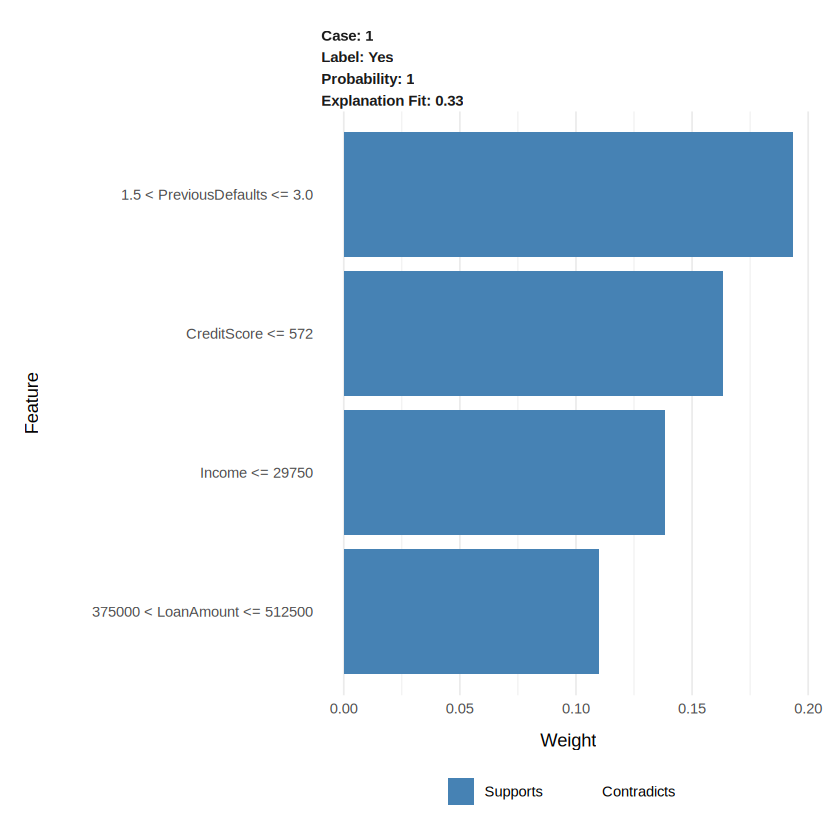

In [14]:
explanation$contradicting <- explanation$feature_weight < 0
plot_features(explanation)

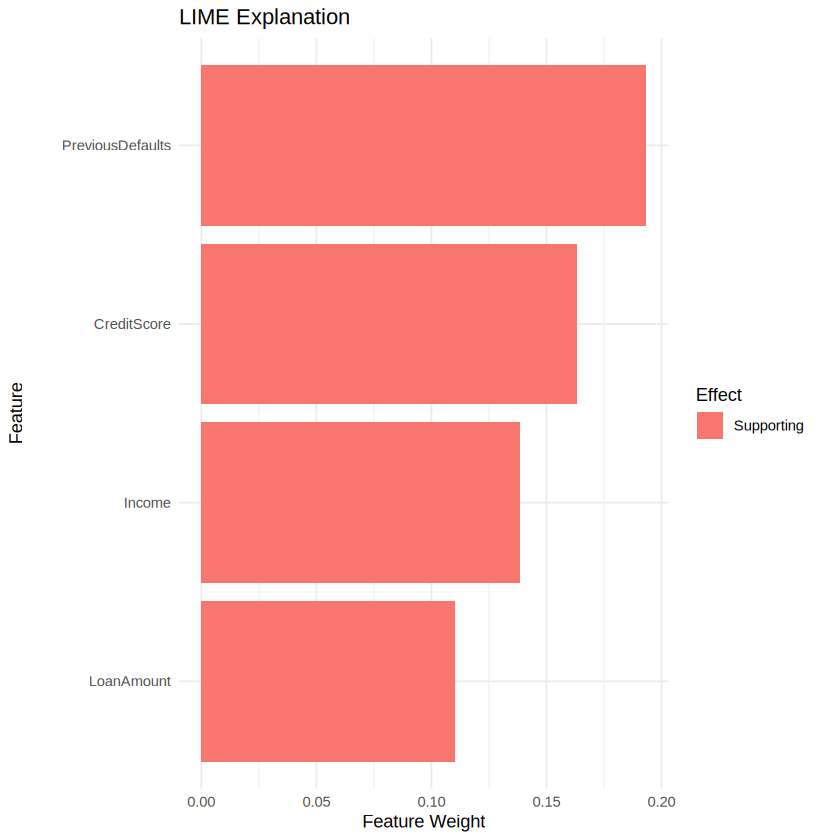

In [15]:
library(ggplot2)

explanation$Type <- ifelse(
  explanation$feature_weight < 0,
  "Contradicting",
  "Supporting"
)

ggplot(
  explanation,
  aes(
    x = reorder(feature, feature_weight),
    y = feature_weight,
    fill = Type
  )
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "LIME Explanation",
    x = "Feature",
    y = "Feature Weight",
    fill = "Effect"
  ) +
  theme_minimal()

In [22]:
fraud_data <- read.csv("credit_card_fraud_dataset.csv")

In [23]:
head(fraud_data)
str(fraud_data)


,TransactionAmount,TransactionTime,MerchantCategory,CustomerAge,PreviousFraud,International,Fraud
,<int>,<int>,<chr>,<int>,<int>,<chr>,<chr>
1,2500,10,Grocery,24,0,No,No
2,450,14,Travel,35,0,No,No
3,120,9,Grocery,29,1,No,No
4,7800,23,Electronics,52,0,Yes,Yes
5,320,11,Restaurant,41,0,No,No
6,15000,2,Online,63,2,Yes,Yes


'data.frame':	50 obs. of  7 variables:
 $ TransactionAmount: int  2500 450 120 7800 320 15000 680 230 9200 540 ...
 $ TransactionTime  : int  10 14 9 23 11 2 16 13 1 15 ...
 $ MerchantCategory : chr  "Grocery" "Travel" "Grocery" "Electronics" ...
 $ CustomerAge      : int  24 35 29 52 41 63 31 27 58 45 ...
 $ PreviousFraud    : int  0 0 1 0 0 2 0 0 1 0 ...
 $ International    : chr  "No" "No" "No" "Yes" ...
 $ Fraud            : chr  "No" "No" "No" "Yes" ...


In [24]:
fraud_data$MerchantCategory<-as.factor(fraud_data$MerchantCategory)
fraud_data$International<-as.factor(fraud_data$International)
fraud_data$Fraud<-as.factor(fraud_data$Fraud)

In [25]:
str(fraud_data)

'data.frame':	50 obs. of  7 variables:
 $ TransactionAmount: int  2500 450 120 7800 320 15000 680 230 9200 540 ...
 $ TransactionTime  : int  10 14 9 23 11 2 16 13 1 15 ...
 $ MerchantCategory : Factor w/ 6 levels "Electronics",..: 3 6 3 1 5 4 3 2 4 5 ...
 $ CustomerAge      : int  24 35 29 52 41 63 31 27 58 45 ...
 $ PreviousFraud    : int  0 0 1 0 0 2 0 0 1 0 ...
 $ International    : Factor w/ 2 levels "No","Yes": 1 1 1 2 1 2 1 1 2 1 ...
 $ Fraud            : Factor w/ 2 levels "No","Yes": 1 1 1 2 1 2 1 1 2 1 ...


In [26]:
fraud_model<-ranger(
  Fraud~TransactionAmount+TransactionTime+MerchantCategory+CustomerAge+PreviousFraud+International,data=fraud_data,probability=TRUE,num.trees=100
)
print(fraud_model)

Ranger result

Call:
 ranger(Fraud ~ TransactionAmount + TransactionTime + MerchantCategory +      CustomerAge + PreviousFraud + International, data = fraud_data,      probability = TRUE, num.trees = 100) 

Type:                             Probability estimation 
Number of trees:                  100 
Sample size:                      50 
Number of independent variables:  6 
Mtry:                             2 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.02332448 


In [27]:
predictions<-predict(fraud_model,fraud_data)
print(predictions$predictions)

               No        Yes
 [1,] 0.992500000 0.00750000
 [2,] 0.977000000 0.02300000
 [3,] 0.975797619 0.02420238
 [4,] 0.075690476 0.92430952
 [5,] 1.000000000 0.00000000
 [6,] 0.004472222 0.99552778
 [7,] 1.000000000 0.00000000
 [8,] 1.000000000 0.00000000
 [9,] 0.012388889 0.98761111
[10,] 0.990000000 0.01000000
[11,] 0.989583333 0.01041667
[12,] 0.895440476 0.10455952
[13,] 0.986214286 0.01378571
[14,] 0.989583333 0.01041667
[15,] 0.103162698 0.89683730
[16,] 0.006138889 0.99386111
[17,] 0.996250000 0.00375000
[18,] 0.986214286 0.01378571
[19,] 0.004472222 0.99552778
[20,] 1.000000000 0.00000000
[21,] 0.977000000 0.02300000
[22,] 0.936047619 0.06395238
[23,] 0.989583333 0.01041667
[24,] 0.050662698 0.94933730
[25,] 0.954964286 0.04503571
[26,] 0.012388889 0.98761111
[27,] 0.996000000 0.00400000
[28,] 1.000000000 0.00000000
[29,] 0.004472222 0.99552778
[30,] 1.000000000 0.00000000
[31,] 0.977000000 0.02300000
[32,] 0.895940476 0.10405952
[33,] 0.199059524 0.80094048
[34,] 1.000000

In [28]:
explainer<-lime(
  fraud_data[,c(
    "TransactionAmount",
    "TransactionTime",
    "MerchantCategory",
    "CustomerAge",
    "PreviousFraud",
    "International")],
fraud_model
)

In [29]:
transaction<-fraud_data[1,c(
  "TransactionAmount",
  "TransactionTime",
  "MerchantCategory",
  "CustomerAge",
  "PreviousFraud",
  "International")]
print(transaction)


  TransactionAmount TransactionTime MerchantCategory CustomerAge PreviousFraud
1              2500              10          Grocery          24             0
  International
1            No


In [30]:
explanation<-explain(
  transaction,
  explainer,
  labels="Yes",
  n_features=5)
print(explanation)

# A tibble: 5 × 13
  model_type    case  label label_prob model_r2 model_intercept model_prediction
  <chr>         <chr> <chr>      <dbl>    <dbl>           <dbl>            <dbl>
1 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
2 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
3 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
4 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
5 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
# ℹ 6 more variables: feature <chr>, feature_value <int>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>


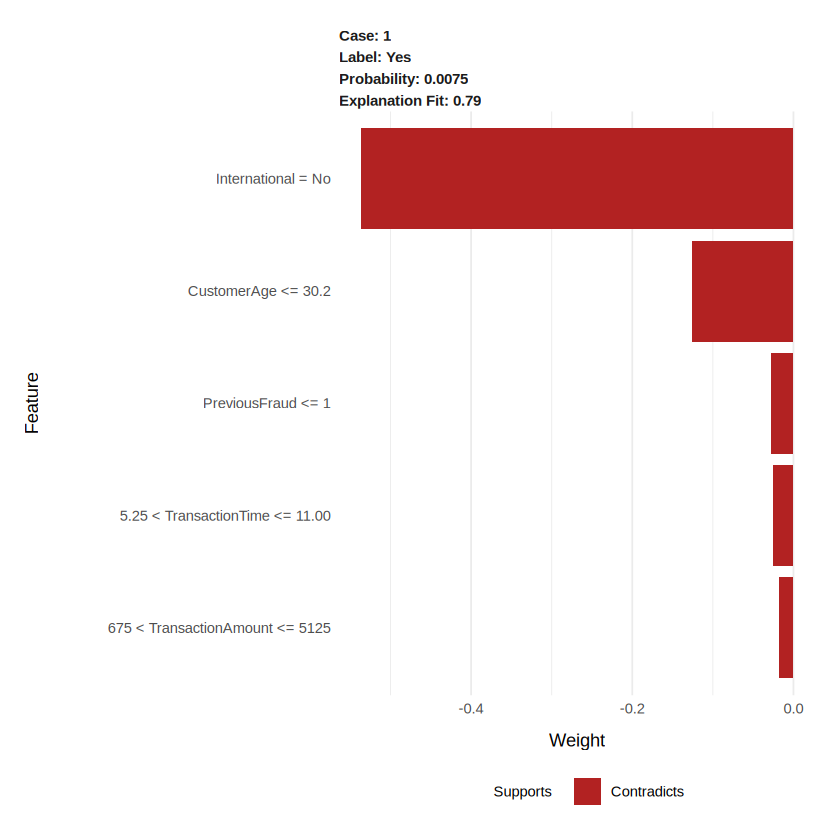

In [31]:
plot_features(explanation)

In [32]:
supporting_features<-explanation[
  explanation$feature_weight>0,]
contradicting_features<-explanation[
  explanation$feature_weight<0,]
print("Features supporting Fraud:")
print(supporting_features)
print("Features contradicting Fraud:")
print(contradicting_features)

[1] "Features supporting Fraud:"
# A tibble: 0 × 13
# ℹ 13 variables: model_type <chr>, case <chr>, label <chr>, label_prob <dbl>,
#   model_r2 <dbl>, model_intercept <dbl>, model_prediction <dbl>,
#   feature <chr>, feature_value <int>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>
[1] "Features contradicting Fraud:"
# A tibble: 5 × 13
  model_type    case  label label_prob model_r2 model_intercept model_prediction
  <chr>         <chr> <chr>      <dbl>    <dbl>           <dbl>            <dbl>
1 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
2 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
3 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
4 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
5 classificati… 1     Yes       0.0075    0.794           0.788           0.0528
# ℹ 6 more variables: feature <chr>, feature_value <int>, featu